In [6]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
from scipy import stats
df = pd.read_csv("Assignment2.csv")
df.head()

,date,dc,rmrf,smb,hml,rf,R1,R2,R3,R4,R5,R6,R7,R8,R9,R10
0,1952,1.039208,0.1180,-0.0702,0.0405,0.0166,0.1432,0.0982,0.1471,0.1852,0.1291,0.0931,0.1288,0.1617,0.0508,0.3209
1,1953,0.996975,-0.0105,-0.0080,-0.0870,0.0182,0.0414,0.0282,-0.0124,0.0008,0.0375,-0.0207,-0.0730,-0.0280,-0.0719,-0.1455
2,1954,1.034664,0.4935,-0.0246,0.2574,0.0086,0.5228,0.3877,0.4527,0.4116,0.5855,0.6271,0.5594,0.8194,0.6587,0.7037
3,1955,1.033162,0.2375,-0.0676,0.0571,0.0157,0.3215,0.2087,0.2185,0.2596,0.2059,0.2475,0.1886,0.3581,0.2485,0.1853
4,1956,1.011275,0.0590,-0.0138,-0.0107,0.0246,0.0372,0.0911,0.1006,0.1424,0.2034,0.1000,0.0962,0.0811,0.0529,-0.0093


In [10]:
#2a:
#calculate factor means and standard errors
factors = ["rmrf", "smb", "hml"]
factor_means = df[factors].mean()
factor_se = df[factors].std() / np.sqrt(len(df))

print(factor_means)
print(factor_se)


rmrf    0.078687
smb     0.026444
hml     0.049111
dtype: float64
rmrf    0.023094
smb     0.016343
hml     0.016317
dtype: float64


In [14]:
#betas from 1
assets = [f"R{i}" for i in range(1, 11)]
Re = df[assets].sub(df["rf"], axis=0)

X = sm.add_constant(df[factors])

betas = []

for asset in assets:
    model = sm.OLS(Re[asset], X).fit()
    betas.append(model.params[factors].values)
    
#run regressions
B = sm.add_constant(np.array(betas))

risk_premia = []

for t in range(len(df)):
    y = Re.iloc[t].values
    model = sm.OLS(y, B).fit()
    risk_premia.append(model.params)

risk_premia = pd.DataFrame(
    risk_premia,
    columns=["Intercept", "rmrf", "smb", "hml"]
)

#calculate estimates 
fm_mean = risk_premia.mean()
fm_se = risk_premia.std() / np.sqrt(len(risk_premia))
fm_t = fm_mean / fm_se

print(pd.DataFrame({
    "Estimate": fm_mean,
    "Std. Error": fm_se,
    "t-stat": fm_t
}).round(4))

#table 
table_2a = pd.DataFrame({
    "FM Estimate": fm_mean,
    "FM Std. Error": fm_se,
    "FM t-stat": fm_t,
    "Factor Mean": factor_means,
    "Factor Std. Error": factor_se,
    "Factor t-stat": factor_means / factor_se
})

display(table_2a.round(4))

           Estimate  Std. Error  t-stat
Intercept    0.0256      0.0478  0.5357
rmrf         0.0582      0.0530  1.0968
smb          0.0376      0.0429  0.8772
hml          0.0278      0.0203  1.3687


,FM Estimate,FM Std. Error,FM t-stat,Factor Mean,Factor Std. Error,Factor t-stat
Intercept,0.0256,0.0478,0.5357,NaN,NaN,NaN
hml,0.0278,0.0203,1.3687,0.0491,0.0163,3.0099
rmrf,0.0582,0.0530,1.0968,0.0787,0.0231,3.4072
smb,0.0376,0.0429,0.8772,0.0264,0.0163,1.6181


In [15]:
#2b
#calculate excess return
predicted_returns = np.array(betas) @ fm_mean[factors].values

results_2b = pd.DataFrame({
    "Asset": assets,
    "Actual Return": Re.mean().values,
    "Predicted Return": predicted_returns
})

display(results_2b.round(4))


,Asset,Actual Return,Predicted Return
0,R1,0.0706,0.0446
1,R2,0.0771,0.0489
2,R3,0.0800,0.0547
3,R4,0.0816,0.0603
4,R5,0.0874,0.0629
5,R6,0.0973,0.0636
6,R7,0.0884,0.0765
7,R8,0.1105,0.0855
8,R9,0.1232,0.0887
9,R10,0.1297,0.1042


In [16]:
#2c
#compare risk premia
comparison = pd.DataFrame({
    "Fama-MacBeth Estimate": fm_mean[factors] * 100,
    "Historical Factor Mean": factor_means * 100
})

display(comparison.round(2))


,Fama-MacBeth Estimate,Historical Factor Mean
rmrf,5.82,7.87
smb,3.76,2.64
hml,2.78,4.91


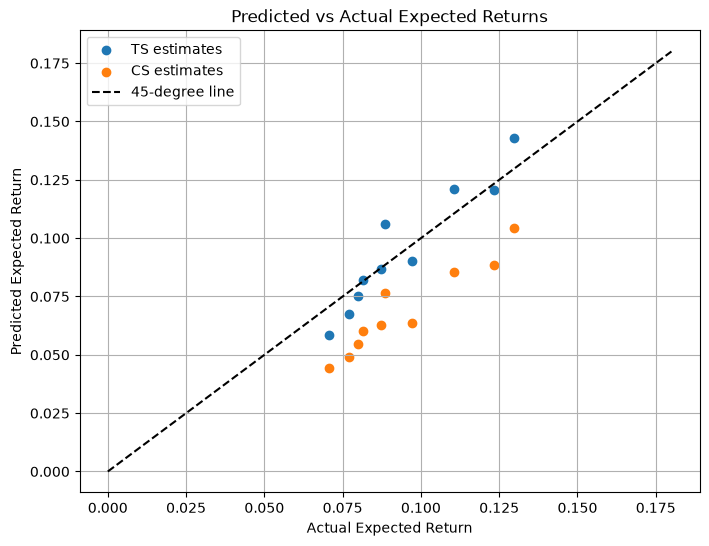

In [18]:
#2d
#graph
import matplotlib.pyplot as plt
actual = Re.mean().values

TS = np.array(betas) @ factor_means[factors].values
CS = np.array(betas) @ fm_mean[factors].values

#plot
plt.figure(figsize=(8, 6))

plt.scatter(actual, TS, label="TS estimates")
plt.scatter(actual, CS, label="CS estimates")

plt.plot([0, 0.18], [0, 0.18], "k--", label="45-degree line")

plt.xlabel("Actual Expected Return")
plt.ylabel("Predicted Expected Return")
plt.title("Predicted vs Actual Expected Returns")
plt.legend()
plt.grid(True)
plt.show()